In [1]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
shawon10_ckplus_path = kagglehub.dataset_download('shawon10/ckplus')

print('Data source import complete.')


Using Colab cache for faster access to the 'ckplus' dataset.
Data source import complete.


In [2]:
shawon10_ckplus_path

'/kaggle/input/ckplus'

In [3]:
ls /root/.cache/kagglehub/datasets/shawon10/ckplus/versions/1

ls: cannot access '/root/.cache/kagglehub/datasets/shawon10/ckplus/versions/1': No such file or directory


In [4]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/ckplus/ck/CK+48/surprise/S071_001_00000012.png
/kaggle/input/ckplus/ck/CK+48/surprise/S082_001_00000013.png
/kaggle/input/ckplus/ck/CK+48/surprise/S116_001_00000013.png
/kaggle/input/ckplus/ck/CK+48/surprise/S097_001_00000020.png
/kaggle/input/ckplus/ck/CK+48/surprise/S085_003_00000013.png
/kaggle/input/ckplus/ck/CK+48/surprise/S127_001_00000015.png
/kaggle/input/ckplus/ck/CK+48/surprise/S085_003_00000011.png
/kaggle/input/ckplus/ck/CK+48/surprise/S107_001_00000008.png
/kaggle/input/ckplus/ck/CK+48/surprise/S138_004_00000013.png
/kaggle/input/ckplus/ck/CK+48/surprise/S068_003_00000013.png
/kaggle/input/ckplus/ck/CK+48/surprise/S126_004_00000010.png
/kaggle/input/ckplus/ck/CK+48/surprise/S068_003_00000014.png
/kaggle/input/ckplus/ck/CK+48/surprise/S090_002_00000010.png
/kaggle/input/ckplus/ck/CK+48/surprise/S100_002_00000014.png
/kaggle/input/ckplus/ck/CK+48/surprise/S063_001_00000011.png
/kaggle/input/ckplus/ck/CK+48/surprise/S052_001_00000014.png
/kaggle/input/ckplus/ck/

In [6]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
#import utils
import os
%matplotlib inline

# Install tensorflow if not already installed
!pip install tensorflow

import tensorflow as tf
from skimage.color import rgb2gray
from tensorflow.keras import Input
from tensorflow.keras.models import Model, load_model, save_model
from tensorflow.keras.layers import Input, Activation, BatchNormalization, Dropout, Lambda, Conv2D, Conv2DTranspose, MaxPooling2D, concatenate, Flatten, Dense, Reshape, Multiply, Add,UpSampling2D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint


import tensorflow as tf
from keras import regularizers
from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img
from tensorflow.keras.layers import Dense, Input, Dropout,Flatten, Conv2D
from tensorflow.keras.layers import BatchNormalization, Activation, MaxPooling2D
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.utils import plot_model

from IPython.display import SVG, Image
# from livelossplot import PlotLossesTensorFlowKeras
print("Tensorflow version:", tf.__version__)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 796.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 102.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 77.7 MB/s eta 0:00:00
  Attempting uninstall: h5py
    Found existing installation: h5py 3.16.0
    Uninstalling h5py-3.16.0:
      Successfully uninstalled h5py-3.16.0


/usr/local/lib/python3.12/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


Tensorflow version: 2.21.0


In [8]:
!pip install opencv-python
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os,cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pylab import rcParams
rcParams['figure.figsize'] = 20, 10

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.9 MB 18.5 MB/s eta 0:00:00


In [9]:
data_path = shawon10_ckplus_path+'/CK+48'
data_dir_list = os.listdir(data_path)

img_rows=256
img_cols=256
num_channel=1

num_epoch=10

img_data_list=[]


for dataset in data_dir_list:
    img_list=os.listdir(data_path+'/'+ dataset)
    print ('Loaded the images of dataset-'+'{}\n'.format(dataset))
    for img in img_list:
        input_img=cv2.imread(data_path + '/'+ dataset + '/'+ img )
        #input_img=cv2.cvtColor(input_img, cv2.COLOR_BGR2GRAY)
        input_img_resize=cv2.resize(input_img,(48,48))
        img_data_list.append(input_img_resize)

img_data = np.array(img_data_list)
img_data = img_data.astype('float32')
img_data = img_data/255
img_data.shape

Loaded the images of dataset-surprise

Loaded the images of dataset-fear

Loaded the images of dataset-sadness

Loaded the images of dataset-disgust

Loaded the images of dataset-contempt

Loaded the images of dataset-happy

Loaded the images of dataset-anger



(981, 48, 48, 3)

In [10]:
num_classes = 7

num_of_samples = img_data.shape[0]
labels = np.ones((num_of_samples,),dtype='int64')

labels[0:248]=0 #249
labels[249:323]=1 #75
labels[324:407]=2 #84
labels[408:584]=3 #177
labels[585:638]=4 #54
labels[639:845]=5 #207
labels[846:980]=6 #135

names = ['surprise','fear','sadness','disgust' ,'contempt','happy','anger']

def getLabel(id):
    return ['surprise','fear','sadness','disgust' ,'contempt','happy','anger'][id]

In [11]:
from tensorflow.keras.utils import to_categorical
Y = to_categorical(labels, num_classes)


#Shuffle the dataset
x,y = shuffle(img_data,Y, random_state=2)
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.15, random_state=2)
x_test=X_test

In [12]:
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import os,cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pylab import rcParams
rcParams['figure.figsize'] = 20, 10

from sklearn.utils import shuffle
from sklearn.model_selection import train_test_split

In [13]:
import tensorflow as tf
import tensorflow.keras as keras
import keras.layers as layers
import numpy as np


class StandardizedConv2DWithOverride(layers.Conv2D):
    def convolution_op(self, inputs, kernel):
        mean, var = tf.nn.moments(kernel, axes=[0, 1, 2], keepdims=True)
        return tf.nn.conv2d(
            inputs,
            (kernel - mean) / tf.sqrt(var + 1e-10),
            padding="VALID",
            strides=list(self.strides),
            name=self.__class__.__name__,
        )

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Input layer
input_layer = layers.Input(shape=(48, 48, 3))

# Standardized Conv2D Layer (Override)
x = layers.Conv2D(32, (3, 3), padding='same')(input_layer)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(32, (3, 3), padding='same')(x)
x = layers.Conv2D(32, (3, 3), padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.Conv2D(32, (3, 3), padding='same')(x)
x = layers.MaxPooling2D()(x)

# Concatenate Layers
y = layers.Conv2D(32, (3, 3), padding='same')(x)
x = layers.Concatenate()([x, y])

# Further Conv2D and Concatenate Layers
x = layers.BatchNormalization()(x)
x = layers.Conv2D(64, (3, 3), padding='same')(x)
x = layers.Conv2D(64, (3, 3), padding='same')(x)
x = layers.Conv2D(64, (3, 3), padding='same')(x)
x = layers.BatchNormalization()(x)
x = layers.MaxPooling2D()(x)

# Conv2D Blocks for deeper layers
x = layers.Conv2D(128, (3, 3), padding='same')(x)
x = layers.Conv2D(128, (3, 3), padding='same')(x)
x = layers.Conv2D(128, (3, 3), padding='same')(x)

# MaxPooling and Batch Normalization
x = layers.MaxPooling2D()(x)
x = layers.BatchNormalization()(x)

# Final Layers
x = layers.Conv2D(256, (3, 3), padding='same')(x)
x = layers.Conv2D(256, (3, 3), padding='same')(x)
x = layers.Conv2D(64, (3, 3), padding='same')(x)
x = layers.Conv2D(256, (3, 3), padding='same')(x)
x = layers.Conv2D(256, (3, 3), padding='same')(x)

# Further MaxPooling
x = layers.MaxPooling2D()(x)
x = layers.BatchNormalization()(x)

# Concatenate and Final Conv2D Layer
x = layers.Conv2D(512, (3, 3), padding='same')(x)
x = layers.BatchNormalization()(x)

# Flatten, Dropout, Dense layers
x = layers.Flatten()(x)
x = layers.Dropout(0.5)(x)
x = layers.Dense(1024, activation='relu')(x)
x = layers.Dropout(0.5)(x)
output_layer = layers.Dense(7, activation='softmax')(x)

# Final Model
model = models.Model(inputs=input_layer, outputs=output_layer)

# Compile the model
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

# Summary of the model
model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 48, 48, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 48, 48,    │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 48, 48,    │        128 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 48, 48,    │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 48, 48,    │      9,248 │ conv2d_1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 48, 48,    │        128 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 48, 48,    │      9,248 │ batch_normalizat… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 24, 24,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 24, 24,    │      9,248 │ max_pooling2d[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 24, 24,    │          0 │ max_pooling2d[0]… │
│ (Concatenate)       │ 64)               │            │ conv2d_4[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 24, 24,    │        256 │ concatenate[0][0] │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 24, 24,    │     36,928 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 24, 24,    │     36,928 │ conv2d_5[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 24, 24,    │     36,928 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 24, 24,    │        256 │ conv2d_7[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 12, 12,    │          0 │ batch_normalizat… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 12, 12,    │     73,856 │ max_pooling2d_1[

 Total params: 8,199,559 (31.28 MB)

 Trainable params: 8,197,383 (31.27 MB)

 Non-trainable params: 2,176 (8.50 KB)

In [15]:
from tensorflow.keras.callbacks import ModelCheckpoint

# Define the ModelCheckpoint callback
checkpoint_callback = ModelCheckpoint(
    'best_model.keras',                      # File path to save the model
    monitor='val_accuracy',               # Monitor the validation accuracy
    mode='max',                            # Save the model with the highest validation accuracy
    save_best_only=True,                   # Only save the best model
    verbose=1                              # Display when saving
)

# Fit the model with the ModelCheckpoint callback
history = model.fit(
    X_train,               # Input training data
    y_train,               # Labels for training data
    epochs=300,            # Number of epochs
    batch_size=32,         # Batch size
    validation_data=(X_test, y_test),  # Validation data
    callbacks=[checkpoint_callback],   # Add the checkpoint callback
    verbose=2              # Display progress
)


Epoch 1/300

Epoch 1: val_accuracy improved from None to 0.12838, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
27/27 - 21s - 780ms/step - accuracy: 0.1993 - loss: 7.7608 - val_accuracy: 0.1284 - val_loss: 148.2498
Epoch 2/300

Epoch 2: val_accuracy improved from 0.12838 to 0.29730, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
27/27 - 16s - 602ms/step - accuracy: 0.3770 - loss: 4.1232 - val_accuracy: 0.2973 - val_loss: 14.7678
Epoch 3/300

Epoch 3: val_accuracy did not improve from 0.29730
27/27 - 16s - 580ms/step - accuracy: 0.4790 - loss: 1.8472 - val_accuracy: 0.2297 - val_loss: 26.3747
Epoch 4/300

Epoch 4: val_accuracy improved from 0.29730 to 0.40541, saving model to best_model.keras

Epoch 4: finished saving model to best_model.keras
27/27 - 16s - 591ms/step - accuracy: 0.5294 - loss: 1.3851 - val_accuracy: 0.4054 - val_loss: 1.4254
Epoch 5/300

Epoch 5: val_accuracy did not improve from 0.40541
27/27

In [16]:
X_train.shape

(833, 48, 48, 3)

In [17]:
y_train.shape

(833, 7)

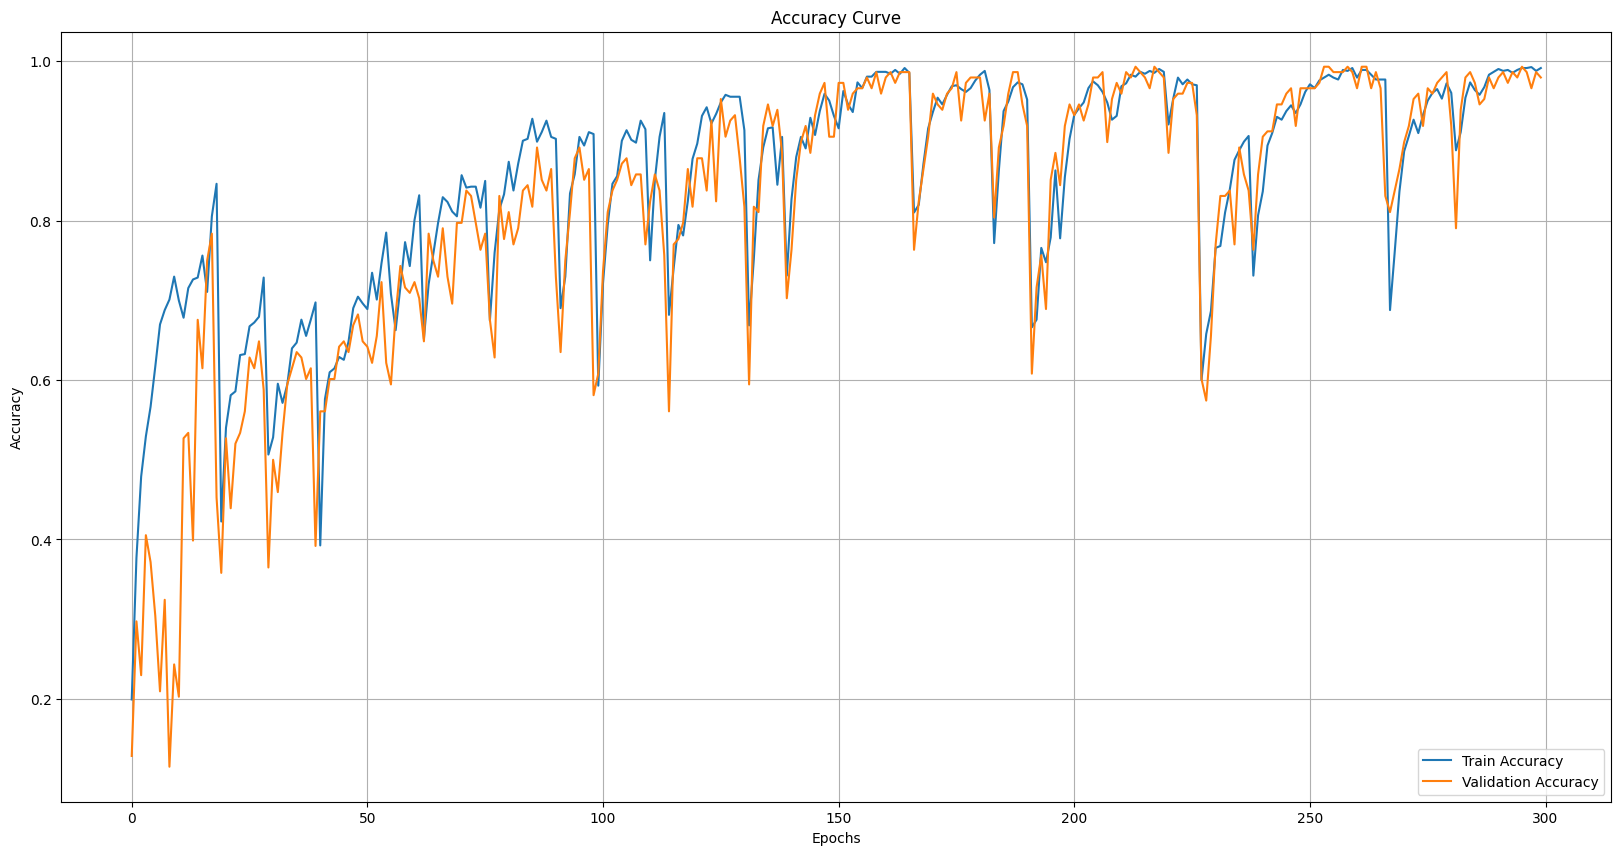

In [18]:
import matplotlib.pyplot as plt

# Plot training and validation accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy Curve')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 152ms/step


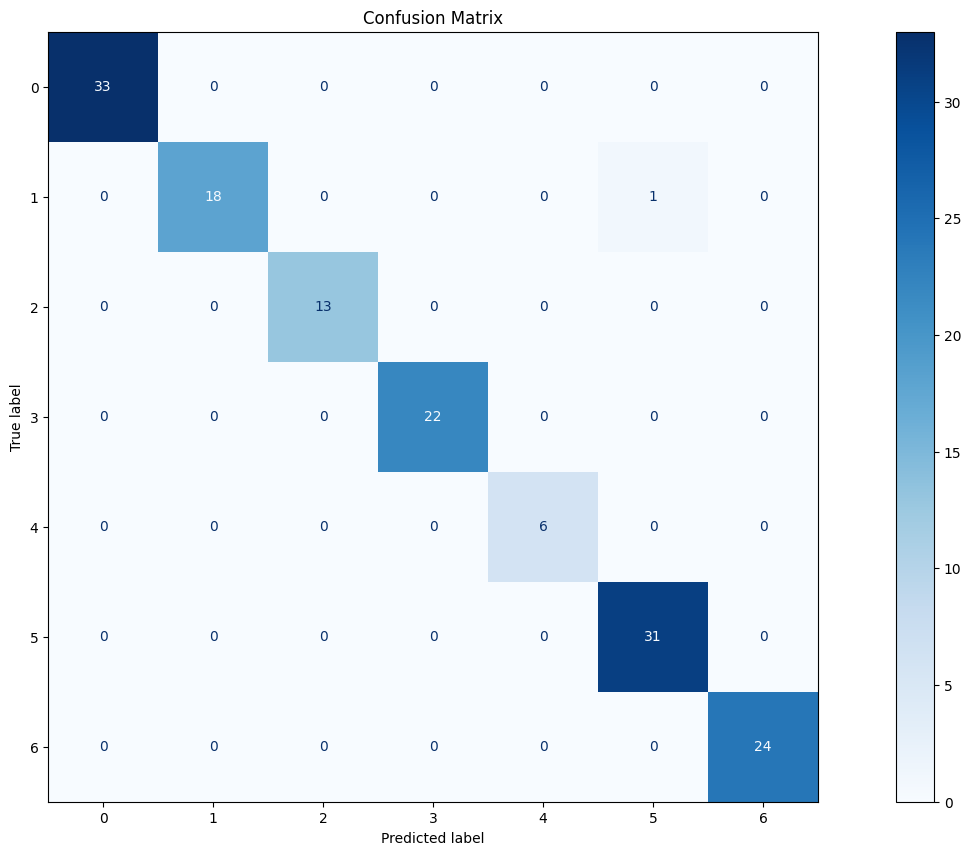

In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np
model=load_model('best_model.keras')
# Make predictions on the test set
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)  # Get the predicted class indices
y_true_classes = np.argmax(y_test, axis=1)  # True class indices

# Compute confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix')
plt.show()


In [20]:
from sklearn.metrics import classification_report
import numpy as np

# Make predictions on the test set
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)  # Get the predicted class indices
y_true_classes = np.argmax(y_test, axis=1)  # True class indices

# Get the classification report
report = classification_report(y_true_classes, y_pred_classes)

# Print the classification report
print(report)


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 127ms/step
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        33
           1       1.00      0.95      0.97        19
           2       1.00      1.00      1.00        13
           3       1.00      1.00      1.00        22
           4       1.00      1.00      1.00         6
           5       0.97      1.00      0.98        31
           6       1.00      1.00      1.00        24

    accuracy                           0.99       148
   macro avg       1.00      0.99      0.99       148
weighted avg       0.99      0.99      0.99       148



1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 193ms/step
Actual Class: surprise, Predicted Class: surprise


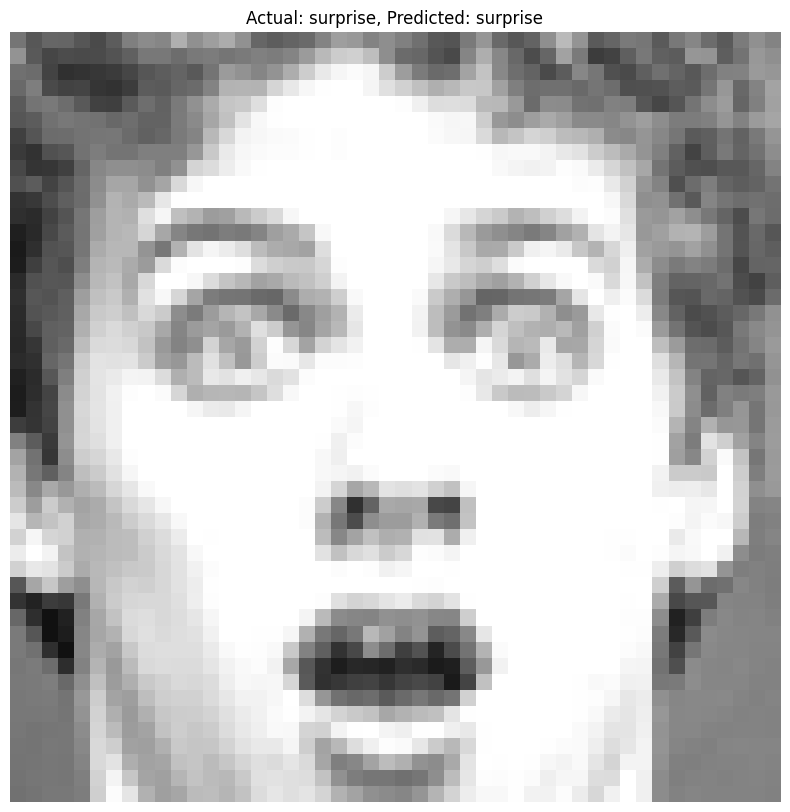

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Actual Class: fear, Predicted Class: fear


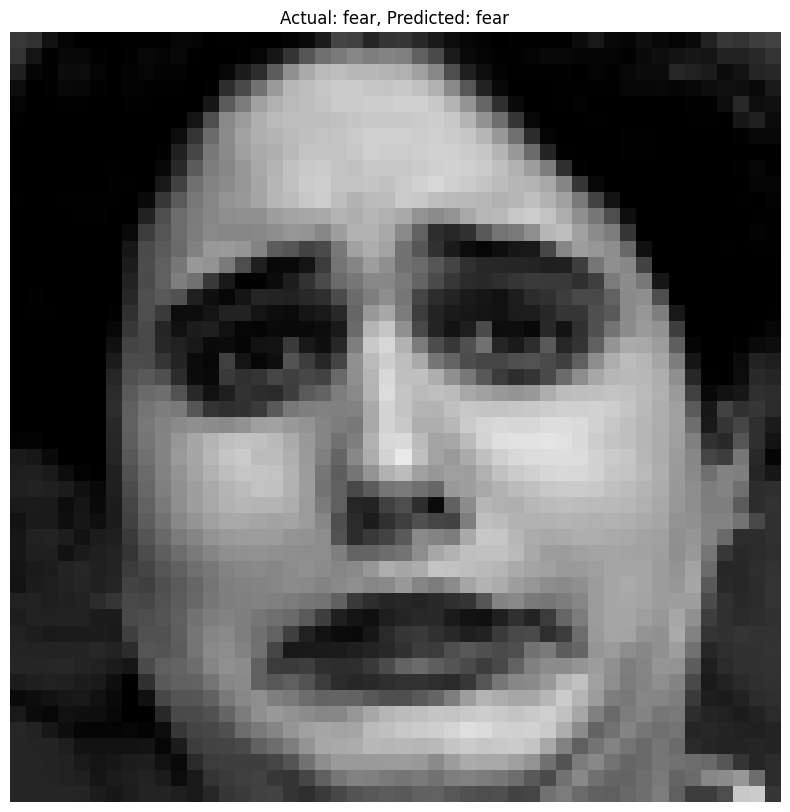

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Actual Class: sadness, Predicted Class: sadness


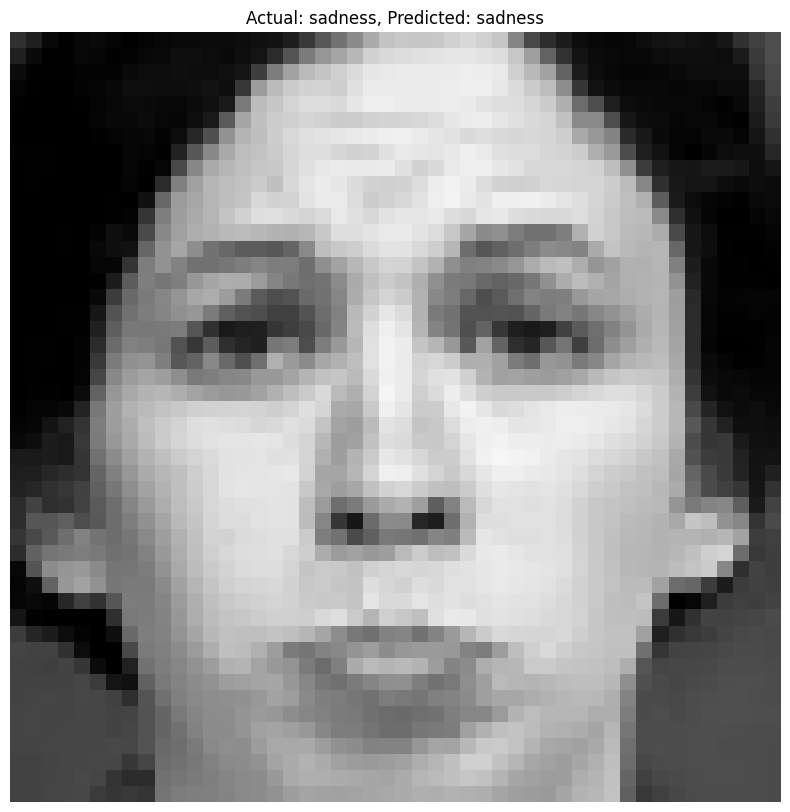

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Actual Class: disgust, Predicted Class: disgust


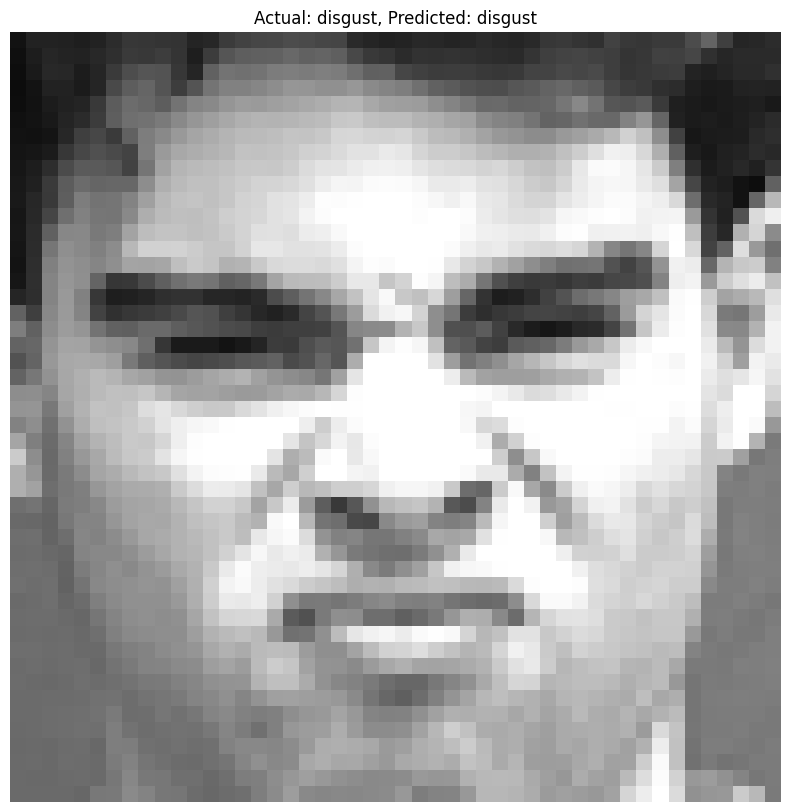

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
Actual Class: contempt, Predicted Class: contempt


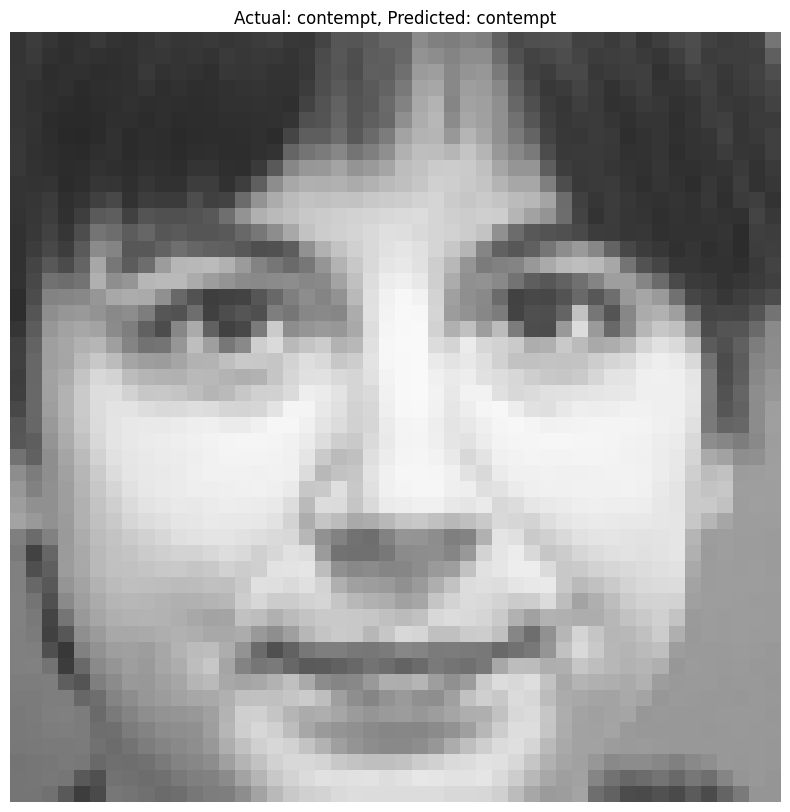

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Actual Class: happy, Predicted Class: happy


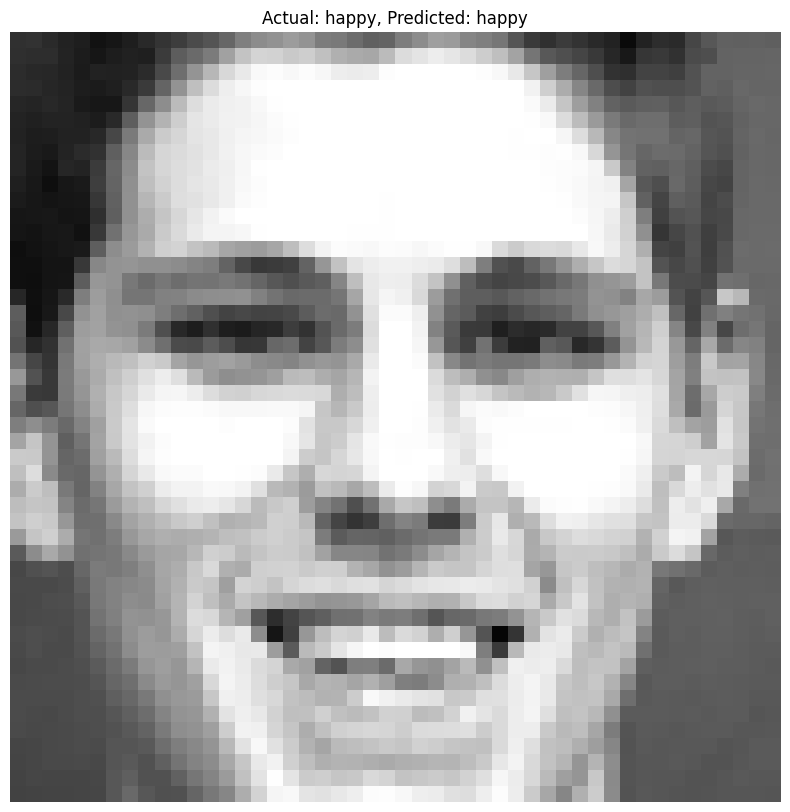

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
Actual Class: anger, Predicted Class: anger


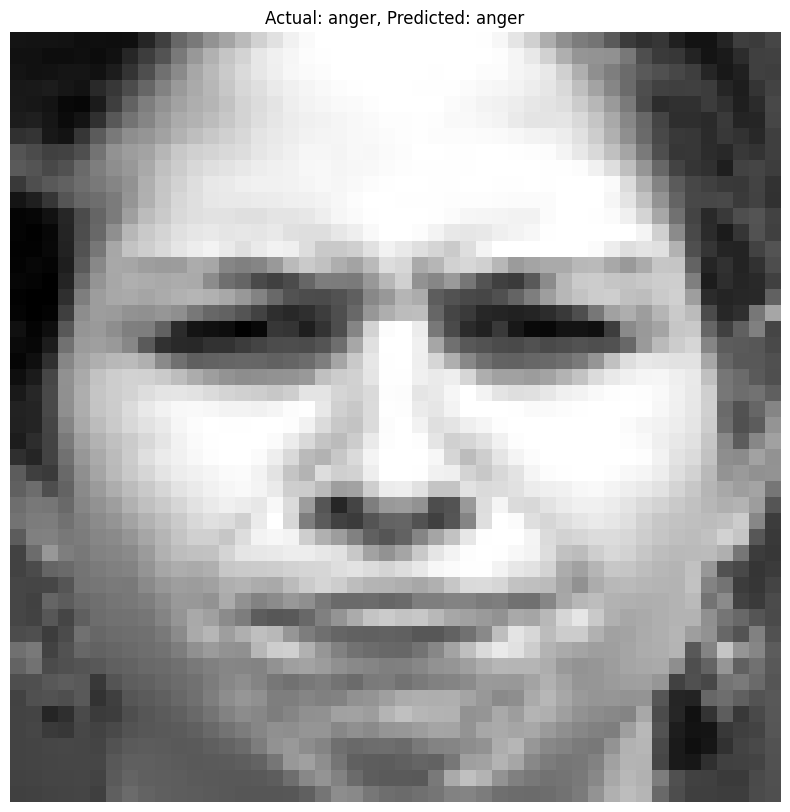

In [21]:
import os
import numpy as np
import cv2
import random
from tensorflow.keras.models import load_model
import matplotlib.pyplot as plt

# Class names
names = ['surprise', 'fear', 'sadness', 'disgust', 'contempt', 'happy', 'anger']

# Load the best model
best_model = load_model('best_model.keras')

# Function to load and preprocess an image
def load_and_preprocess_image(image_path, target_size=(48, 48)):
    image = cv2.imread(image_path)  # Read the image using OpenCV
    if image is None:
        print(f"Error: Unable to load image at {image_path}")
        return None
    image = cv2.resize(image, target_size)  # Resize the image to the target size
    image = image.astype('float32') / 255.0  # Normalize the image
    image = np.expand_dims(image, axis=0)  # Add batch dimension (1, 48, 48, 3)
    return image

# Path to the CK+48 dataset
dataset_path = '/kaggle/input/ckplus/CK+48'

# Load random image from each class and predict
for class_name in names:
    # Path for the current class
    class_path = os.path.join(dataset_path, class_name)

    # List all the images in the class folder
    image_files = [f for f in os.listdir(class_path) if f.endswith('.png') or f.endswith('.jpg')]

    if image_files:
        # Select a random image file
        random_image_file = random.choice(image_files)
        image_path = os.path.join(class_path, random_image_file)

        # Load and preprocess the image
        random_image = load_and_preprocess_image(image_path)

        if random_image is not None:
            # Predict using the model
            prediction = best_model.predict(random_image)

            # Get the predicted class
            predicted_class = np.argmax(prediction, axis=1)
            print(f"Actual Class: {class_name}, Predicted Class: {names[predicted_class[0]]}")

            # Display the actual and predicted image
            plt.imshow(cv2.cvtColor(random_image[0], cv2.COLOR_BGR2RGB))  # Convert BGR to RGB for correct display
            plt.title(f"Actual: {class_name}, Predicted: {names[predicted_class[0]]}")
            plt.axis('off')  # Hide axes
            plt.show()
